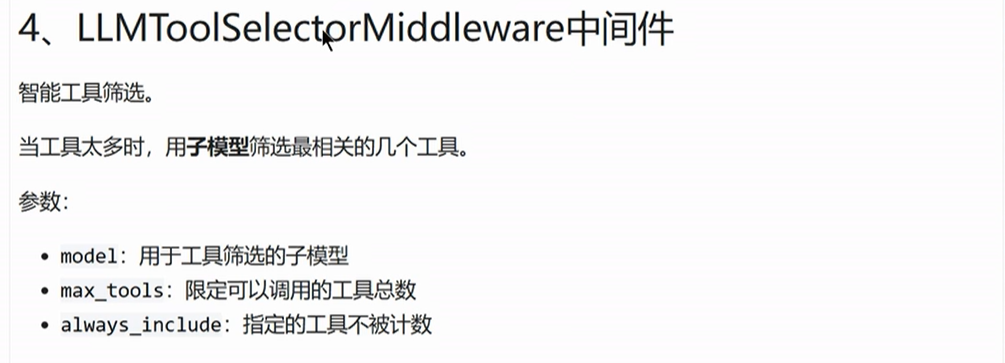

## 举例1

In [1]:

from langchain_core import messages
from langchain.agents.middleware import SummarizationMiddleware, LLMToolSelectorMiddleware
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langchain_core.tools import tool
from typing import Union, Dict, Any
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langgraph.config import get_stream_writer
from rich import print as rprint
from utils.tool_utils import query_weather_from_web,query_news_from_web

# 1.初始化模型需要2个模型应该是model_out直接给agent使用，另外应该model_in,防止中间件里面
model_out = ChatOpenAI(
    model="qwen3-vl:latest",
    # model="483025889/qwen3.5:9b",
    # model="gemma4:12b",
    api_key="sk12345",
    base_url="http://localhost:11434/v1",
)

model_in = ChatOpenAI(
    # model="qwen3-vl:latest",
    model="483025889/qwen3.5:9b",
    # model="gemma4:12b",
    api_key="sk12345",
    base_url="http://localhost:11434/v1",
)

## 定义工具
@tool
def get_weather(city: str):
    """查询指定城市天气"""
    return f"{city}今天天气晴朗"


@tool
def get_news():
    """查询今日国内新闻概要"""
    return ("今日国内新闻概要："
            "中方三艘油轮过航霍尔木兹海峡")


@tool
def calculate(num1: int, num2: int) -> int:
    """
    执行数学计算

    Args:
        num1: 第一个加数
        num2: 第二个加数
    """
    return num1 + num2

@tool
def search_stock(symbol: str):
    """
    查询股票行情

    Args:
        symbol: 股票代码
    """
    return "该股票今天行情不错"

agent = create_agent(
    model=model_out,
    tools=[get_weather, get_news, calculate, search_stock],
    middleware=[
        LLMToolSelectorMiddleware(
            model=model_in,
            max_tools=0,
            always_include=["get_weather"]
        )
    ]
)

resp = agent.invoke({"messages":[HumanMessage("北京今天天气如何？今日新闻概要")]})
for msg in resp["messages"]:
    msg.pretty_print()

================================ Human Message =================================

北京今天天气如何？今日新闻概要
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_bsdjtvrd)
 Call ID: call_bsdjtvrd
  Args:
    city: 北京
================================= Tool Message =================================
Name: get_weather

北京今天天气晴朗
================================== Ai Message ==================================

北京今天天气晴朗。关于今日新闻概要，我目前无法提供实时新闻内容（当前工具仅支持天气查询功能）。需要我为您查询其他信息吗？


## 举例2

In [2]:

from langchain_core import messages
from langchain.agents.middleware import SummarizationMiddleware, LLMToolSelectorMiddleware
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langchain_core.tools import tool
from typing import Union, Dict, Any
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langgraph.config import get_stream_writer
from rich import print as rprint
from utils.tool_utils import query_weather_from_web,query_news_from_web

# 1.初始化模型需要2个模型应该是model_out直接给agent使用，另外应该model_in,防止中间件里面
model_out = ChatOpenAI(
    model="qwen3-vl:latest",
    # model="483025889/qwen3.5:9b",
    # model="gemma4:12b",
    api_key="sk12345",
    base_url="http://localhost:11434/v1",
)

model_in = ChatOpenAI(
    # model="qwen3-vl:latest",
    model="483025889/qwen3.5:9b",
    # model="gemma4:12b",
    api_key="sk12345",
    base_url="http://localhost:11434/v1",
)

## 定义工具
@tool
def get_weather(city: str):
    """查询指定城市天气"""
    return f"{city}今天天气晴朗"


@tool
def get_news():
    """查询今日国内新闻概要"""
    return ("今日国内新闻概要："
            "中方三艘油轮过航霍尔木兹海峡")


@tool
def calculate(num1: int, num2: int) -> int:
    """
    执行数学计算

    Args:
        num1: 第一个加数
        num2: 第二个加数
    """
    return num1 + num2

@tool
def search_stock(symbol: str):
    """
    查询股票行情

    Args:
        symbol: 股票代码
    """
    return "该股票今天行情不错"

agent = create_agent(
    model=model_out,
    tools=[get_weather, get_news, calculate, search_stock],
    middleware=[
        LLMToolSelectorMiddleware(
            model=model_in,
            max_tools=0,
            always_include=["get_news"]
        )
    ]
)

resp = agent.invoke({"messages":[HumanMessage("北京今天天气如何？今日新闻概要")]})
for msg in resp["messages"]:
    msg.pretty_print()

================================ Human Message =================================

北京今天天气如何？今日新闻概要
================================== Ai Message ==================================
Tool Calls:
  get_news (call_1igymmj6)
 Call ID: call_1igymmj6
  Args:
================================= Tool Message =================================
Name: get_news

今日国内新闻概要：中方三艘油轮过航霍尔木兹海峡
================================== Ai Message ==================================

关于北京今日天气，当前工具无法提供天气查询功能。已为您获取今日国内新闻概要：
【今日国内新闻概要】中方三艘油轮过航霍尔木兹海峡

如需其他帮助，请随时告知。


## 举例3

In [3]:

from langchain_core import messages
from langchain.agents.middleware import SummarizationMiddleware, LLMToolSelectorMiddleware
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langchain_core.tools import tool
from typing import Union, Dict, Any
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langgraph.config import get_stream_writer
from rich import print as rprint
from utils.tool_utils import query_weather_from_web,query_news_from_web

# 1.初始化模型需要2个模型应该是model_out直接给agent使用，另外应该model_in,防止中间件里面
model_out = ChatOpenAI(
    model="qwen3-vl:latest",
    # model="483025889/qwen3.5:9b",
    # model="gemma4:12b",
    api_key="sk12345",
    base_url="http://localhost:11434/v1",
)

model_in = ChatOpenAI(
    # model="qwen3-vl:latest",
    model="483025889/qwen3.5:9b",
    # model="gemma4:12b",
    api_key="sk12345",
    base_url="http://localhost:11434/v1",
)

## 定义工具
@tool
def get_weather(city: str):
    """查询指定城市天气"""
    return f"{city}今天天气晴朗"


@tool
def get_news():
    """查询今日国内新闻概要"""
    return ("今日国内新闻概要："
            "中方三艘油轮过航霍尔木兹海峡")


@tool
def calculate(num1: int, num2: int) -> int:
    """
    执行数学计算

    Args:
        num1: 第一个加数
        num2: 第二个加数
    """
    return num1 + num2

@tool
def search_stock(symbol: str):
    """
    查询股票行情

    Args:
        symbol: 股票代码
    """
    return "该股票今天行情不错"

agent = create_agent(
    model=model_out,
    tools=[get_weather, get_news, calculate, search_stock],
    middleware=[
        LLMToolSelectorMiddleware(
            model=model_in,
            max_tools=0,
            always_include=["get_news","get_weather"]
        )
    ]
)

resp = agent.invoke({"messages":[HumanMessage("北京今天天气如何？今日新闻概要")]})
for msg in resp["messages"]:
    msg.pretty_print()

================================ Human Message =================================

北京今天天气如何？今日新闻概要
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_bsat1cmw)
 Call ID: call_bsat1cmw
  Args:
    city: 北京
  get_news (call_fdhusdsy)
 Call ID: call_fdhusdsy
  Args:
================================= Tool Message =================================
Name: get_weather

北京今天天气晴朗
================================= Tool Message =================================
Name: get_news

今日国内新闻概要：中方三艘油轮过航霍尔木兹海峡
================================== Ai Message ==================================

北京今日天气晴朗，适合外出活动~  
今日国内新闻概要：中方三艘油轮过航霍尔木兹海峡。


## 举例4

In [1]:

from langchain_core import messages
from langchain.agents.middleware import SummarizationMiddleware, LLMToolSelectorMiddleware
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langchain_core.tools import tool
from typing import Union, Dict, Any
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langgraph.config import get_stream_writer
from rich import print as rprint
from utils.tool_utils import query_weather_from_web,query_news_from_web

# 1.初始化模型需要2个模型应该是model_out直接给agent使用，另外应该model_in,防止中间件里面
model_out = ChatOpenAI(
    # model="qwen3-vl:latest",
    # model="483025889/qwen3.5:9b", # 在这里不好，不会灵活适配工具
    model="gemma4:12b", # 在这里ok
    api_key="sk12345",
    base_url="http://localhost:11434/v1",
)

model_in = ChatOpenAI(
    model="qwen3-vl:latest",
    # model="483025889/qwen3.5:9b",
    # model="gemma4:12b",
    api_key="sk12345",
    base_url="http://localhost:11434/v1",
)

## 定义工具
@tool
def get_weather(city: str):
    """查询指定城市天气"""
    return f"{city}今天天气晴朗"


@tool
def get_news():
    """查询今日国内新闻概要"""
    return ("今日国内新闻概要："
            "中方三艘油轮过航霍尔木兹海峡")


@tool
def calculate(num1: int, num2: int) -> int:
    """
    执行数学计算

    Args:
        num1: 第一个加数
        num2: 第二个加数
    """
    return num1 + num2

@tool
def search_stock(symbol: str):
    """
    查询股票行情

    Args:
        symbol: 股票代码
    """
    return "该股票今天行情不错"

agent = create_agent(
    model=model_out,
    tools=[get_weather, get_news, calculate, search_stock],
    middleware=[
        LLMToolSelectorMiddleware(
            model=model_in,
            max_tools=1,
            always_include=["get_weather"]
        )
    ]
)

resp = agent.invoke({"messages":[HumanMessage("北京今天天气如何？今日新闻概要")]})
for msg in resp["messages"]:
    msg.pretty_print()

================================ Human Message =================================

北京今天天气如何？今日新闻概要
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_vi834fcp)
 Call ID: call_vi834fcp
  Args:
    city: 北京
================================= Tool Message =================================
Name: get_weather

北京今天天气晴朗
================================== Ai Message ==================================
Tool Calls:
  get_news (call_pumdc4b8)
 Call ID: call_pumdc4b8
  Args:
================================= Tool Message =================================
Name: get_news

今日国内新闻概要：中方三艘油轮过航霍尔木兹海峡
================================== Ai Message ==================================

北京今天天气晴朗。

今日新闻概要：中方三艘油轮过航霍尔木兹海峡。


## 举例5

In [3]:

from langchain_core import messages
from langchain.agents.middleware import SummarizationMiddleware, LLMToolSelectorMiddleware
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langchain_core.tools import tool
from typing import Union, Dict, Any
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langgraph.config import get_stream_writer
from rich import print as rprint
from utils.tool_utils import query_weather_from_web,query_news_from_web

# 1.初始化模型需要2个模型应该是model_out直接给agent使用，另外应该model_in,防止中间件里面
model_out = ChatOpenAI(
    # model="qwen3-vl:latest", # 这里不好用
    # model="483025889/qwen3.5:9b", #这里不好用
    model="gemma4:12b",
    api_key="sk12345",
    base_url="http://localhost:11434/v1",
)

model_in = ChatOpenAI(
    # model="qwen3-vl:latest",
    model="483025889/qwen3.5:9b",
    # model="gemma4:12b",
    api_key="sk12345",
    base_url="http://localhost:11434/v1",
)

## 定义工具
@tool
def get_weather(city: str):
    """查询指定城市天气"""
    return f"{city}今天天气晴朗"


@tool
def get_news():
    """查询今日国内新闻概要"""
    return ("今日国内新闻概要："
            "中方三艘油轮过航霍尔木兹海峡")


@tool
def calculate(num1: int, num2: int) -> int:
    """
    执行数学计算

    Args:
        num1: 第一个加数
        num2: 第二个加数
    """
    return num1 + num2

@tool
def search_stock(symbol: str):
    """
    查询股票行情

    Args:
        symbol: 股票代码
    """
    return "该股票今天行情不错"

agent = create_agent(
    model=model_out,
    tools=[get_weather, get_news, calculate, search_stock],
    middleware=[
        LLMToolSelectorMiddleware(
            model=model_in,
            max_tools=1,
            always_include=["get_news"]
        )
    ]
)

resp = agent.invoke({"messages":[HumanMessage("北京今天天气如何？今日新闻概要")]})
for msg in resp["messages"]:
    msg.pretty_print()

================================ Human Message =================================

北京今天天气如何？今日新闻概要
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_jav3kc07)
 Call ID: call_jav3kc07
  Args:
    city: 北京
================================= Tool Message =================================
Name: get_weather

北京今天天气晴朗
================================== Ai Message ==================================
Tool Calls:
  get_news (call_pvx5agw0)
 Call ID: call_pvx5agw0
  Args:
================================= Tool Message =================================
Name: get_news

今日国内新闻概要：中方三艘油轮过航霍尔木兹海峡
================================== Ai Message ==================================

北京今天天气晴朗。

今日国内新闻概要：中方三艘油轮过航霍尔木兹海峡。
